# Fairness Analysis, Model Stability & Final Project Summary

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

---

## Notebook Objectives

The final stage of the project evaluates the credit risk scoring system from a fairness and business perspective.

The objectives are to:

- Analyze the distribution of predicted credit scores across demographic groups.
- Evaluate whether the model exhibits substantial differences between applicant segments.
- Assess the stability of the generated credit scores.
- Produce a fairness summary report.
- Present the final conclusions of the project.

This notebook completes the end-to-end credit risk scoring workflow by ensuring that model performance is complemented by fairness and interpretability analyses.

# Import Required Libraries

The following libraries are used for fairness analysis, descriptive statistics, visualization, and reporting.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Datasets

Two datasets are required:

- The applicant-level credit scores generated in Notebook 13.
- The original application dataset containing demographic information.

In [2]:
RESULT_DIR = Path("../results")

credit_scores = pd.read_csv(
    RESULT_DIR / "credit_risk_scores.csv"
)

application = pd.read_csv(
    "../data/HC_application_train.csv"
)

print("Credit Scores :", credit_scores.shape)
print("Application   :", application.shape)

Credit Scores : (61503, 6)
Application   : (307511, 122)


# Merge Applicant Information

The generated credit scores are merged with the original applicant demographic information using the applicant identifier (`SK_ID_CURR`).

In [3]:
fairness_df = application.merge(
    credit_scores,
    on="SK_ID_CURR",
    how="inner"
)

fairness_df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,Actual Default,Predicted Default,Default Probability,Credit Score,Risk Band
0,100009,0,Cash loans,F,Y,Y,1,171000.000,1560726.0,41301.0,...,0.0,0.0,1.0,1.0,2.0,0,0,0.010016,894,Excellent
1,100014,0,Cash loans,F,N,Y,1,112500.000,652500.0,21177.0,...,0.0,0.0,1.0,0.0,0.0,0,0,0.047946,871,Excellent
2,100015,0,Cash loans,F,N,Y,0,38419.155,148365.0,10678.5,...,0.0,0.0,0.0,0.0,2.0,0,0,0.021351,887,Excellent
3,100018,0,Cash loans,F,N,Y,0,189000.000,773680.5,32778.0,...,NaN,NaN,NaN,NaN,NaN,0,0,0.022408,887,Excellent
4,100020,0,Cash loans,M,N,N,0,108000.000,509602.5,26149.5,...,0.0,0.0,0.0,1.0,0.0,0,0,0.392082,665,Fair


# Dataset Overview

In [4]:
summary = pd.DataFrame({

    "Metric":[
        "Applicants",
        "Features"
    ],

    "Value":[
        fairness_df.shape[0],
        fairness_df.shape[1]
    ]

})

summary

,Metric,Value
0,Applicants,61503
1,Features,127


# Gender Fairness Analysis

The average default probability and average credit score are compared across gender groups.

In [5]:
gender_summary = (

    fairness_df

    .groupby("CODE_GENDER")

    .agg({

        "Default Probability":"mean",

        "Credit Score":"mean"

    })

    .round(2)

)

gender_summary

,Default Probability,Credit Score
CODE_GENDER,,
F,0.07,858.28
M,0.10,839.19
XNA,0.33,705.00


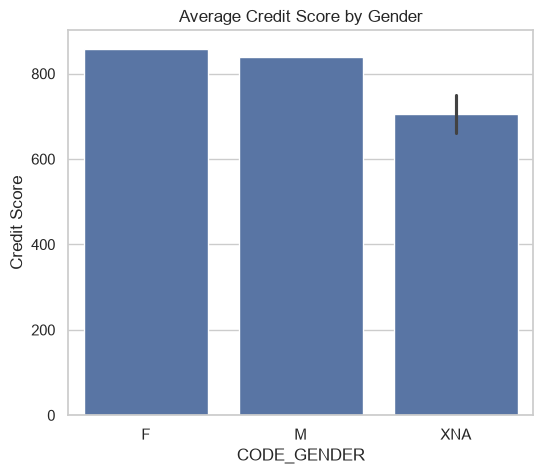

In [6]:
plt.figure(figsize=(6,5))

sns.barplot(

    data=fairness_df,

    x="CODE_GENDER",

    y="Credit Score"

)

plt.title("Average Credit Score by Gender")

plt.show()

# Income Type Fairness Analysis

Average default probabilities and credit scores are compared across applicant income categories.

In [7]:
income_summary = (

    fairness_df

    .groupby("NAME_INCOME_TYPE")

    .agg({

        "Default Probability":"mean",

        "Credit Score":"mean"

    })

    .round(2)

)

income_summary

,Default Probability,Credit Score
NAME_INCOME_TYPE,,
Businessman,0.04,879.00
Commercial associate,0.07,856.00
Maternity leave,0.09,847.50
Pensioner,0.05,867.72
State servant,0.07,856.88
Student,0.11,831.86
Unemployed,0.11,835.60
Working,0.09,843.55


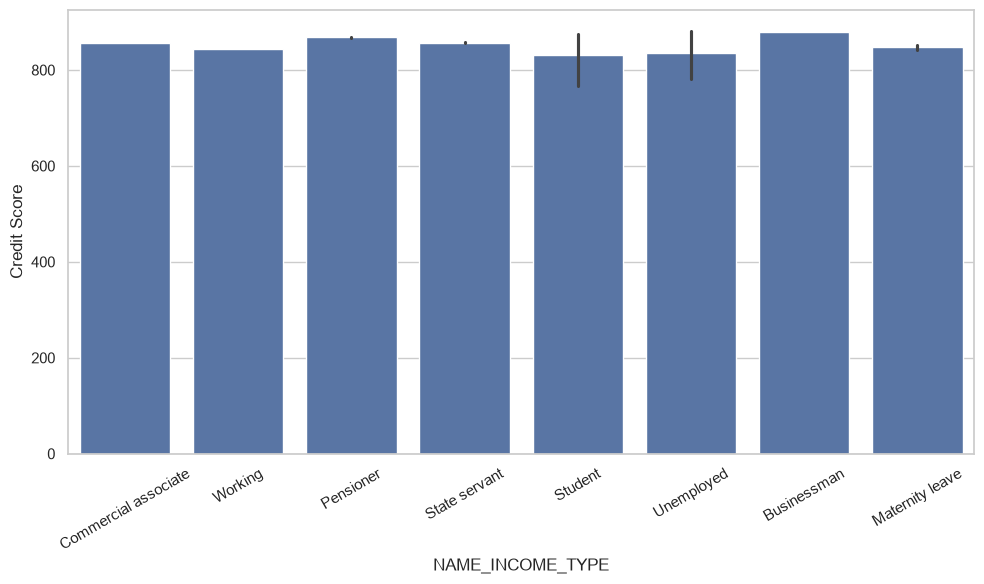

In [8]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=fairness_df,

    x="NAME_INCOME_TYPE",

    y="Credit Score"

)

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

# Education Level Fairness Analysis

The generated credit scores are analyzed across education categories.

In [9]:
education_summary = (

    fairness_df

    .groupby("NAME_EDUCATION_TYPE")

    .agg({

        "Default Probability":"mean",

        "Credit Score":"mean"

    })

    .round(2)

)

education_summary

,Default Probability,Credit Score
NAME_EDUCATION_TYPE,,
Academic degree,0.05,869.45
Higher education,0.05,867.42
Incomplete higher,0.09,848.51
Lower secondary,0.09,845.72
Secondary / secondary special,0.09,846.61


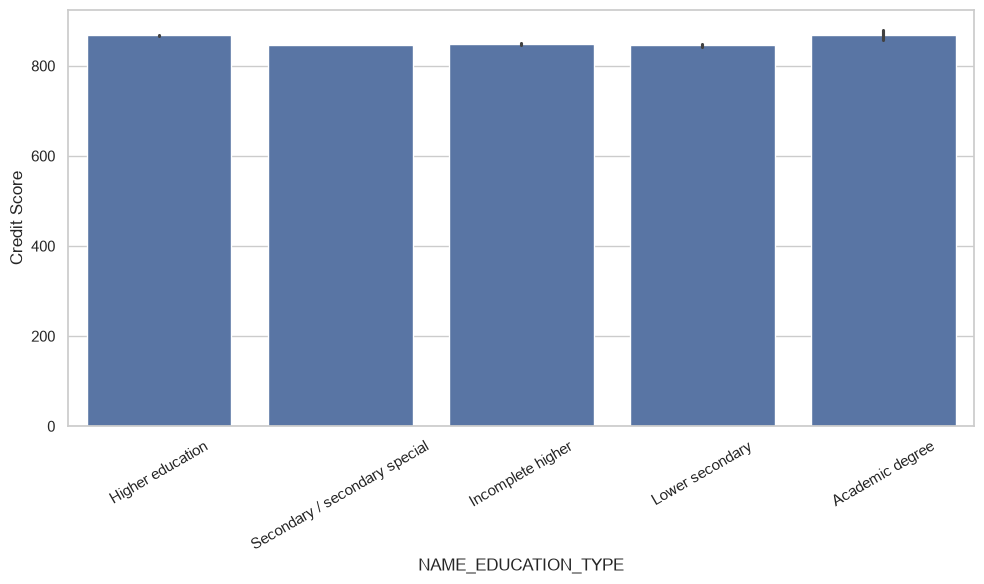

In [10]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=fairness_df,

    x="NAME_EDUCATION_TYPE",

    y="Credit Score"

)

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

# Risk Band Distribution

The distribution of applicants across credit risk bands is examined separately for each gender group.

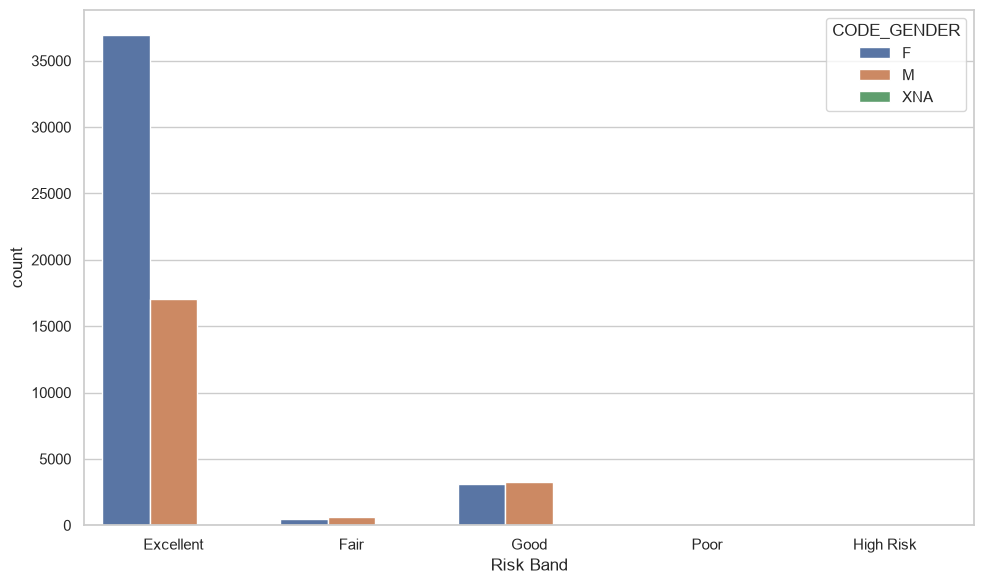

In [11]:
plt.figure(figsize=(10,6))

sns.countplot(

    data=fairness_df,

    x="Risk Band",

    hue="CODE_GENDER"

)

plt.tight_layout()

plt.show()

# Model Stability Analysis

The distribution of predicted default probabilities and generated credit scores provides insight into the consistency of the credit scoring system.

A stable model should produce a smooth distribution of scores without excessive clustering or abrupt discontinuities.

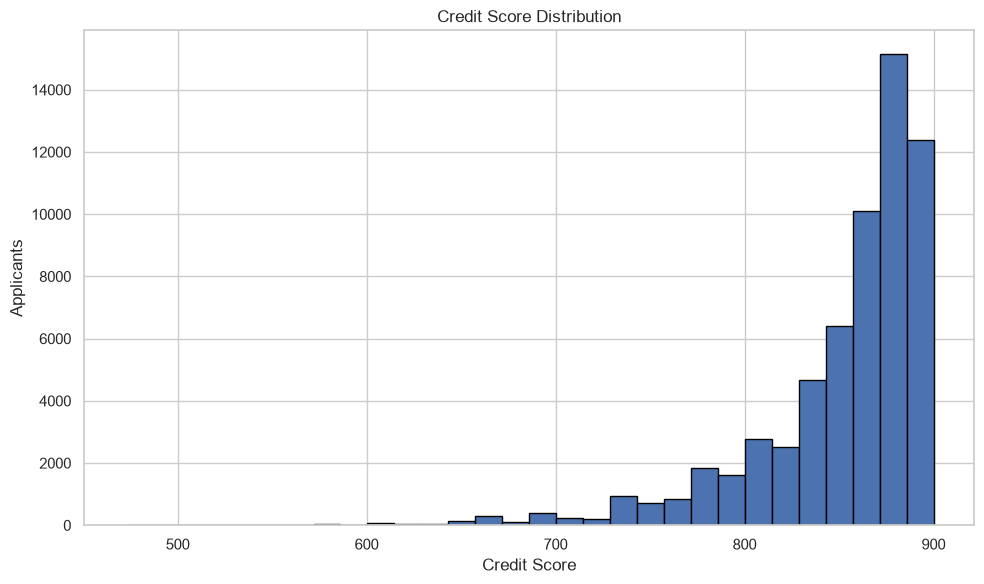

In [12]:
plt.figure(figsize=(10,6))

plt.hist(

    fairness_df["Credit Score"],

    bins=30,

    edgecolor="black"

)

plt.title("Credit Score Distribution")

plt.xlabel("Credit Score")

plt.ylabel("Applicants")

plt.tight_layout()

plt.show()

# Fairness Summary

The following tables summarize the fairness evaluation conducted across the selected demographic groups.

In [13]:
fairness_report = pd.concat(

    {

        "Gender": gender_summary,

        "Income": income_summary,

        "Education": education_summary

    }

)

fairness_report

Default Probability  Credit Score
Gender    F                                             0.07        858.28
          M                                             0.10        839.19
          XNA                                           0.33        705.00
Income    Businessman                                   0.04        879.00
          Commercial associate                          0.07        856.00
          Maternity leave                               0.09        847.50
          Pensioner                                     0.05        867.72
          State servant                                 0.07        856.88
          Student                                       0.11        831.86
          Unemployed                                    0.11        835.60
          Working                                       0.09        843.55
Education Academic degree                               0.05        869.45
          Higher education                              0.05        867.42
          Incomplete higher                             0.09        848.51
          Lower secondary                               0.09        845.72
          Secondary / secondary special                 0.09        846.61

# Save Fairness Report

The fairness analysis results are saved for documentation and future reference.

In [14]:
fairness_report.to_csv(

    RESULT_DIR / "fairness_report.csv"

)

print("Fairness report saved successfully.")

Fairness report saved successfully.


---

# Publication Upgrade: Advanced Fairness Metrics

The descriptive comparison above (mean default probability and mean credit score per
group) shows *whether* groups differ but not by how much relative to accepted
fairness thresholds, and it says nothing about whether the model's **errors** are
distributed unevenly across groups. Four standard, formally defined fairness metrics
from the algorithmic-fairness literature are computed below using the `fairlearn`
package, using the model's actual predictions (`Predicted Default`) and actual outcomes
(`Actual Default`) already present in `fairness_df`:

- **Demographic Parity Difference** — the largest difference, across groups, in the
  rate at which applicants are predicted to default (selection rate). Zero means every
  group is flagged as high-risk at the same rate.
- **Disparate Impact Ratio** (fairlearn's `demographic_parity_ratio`) — the ratio of
  the lowest to the highest group selection rate. This is the same quantity used in the
  US Equal Employment Opportunity Commission's "four-fifths rule": a ratio below 0.8 is
  a commonly cited (though not universally binding) threshold for concern.
- **Equal Opportunity Difference** — the largest difference, across groups, in the
  **true positive rate** (recall) among applicants who actually defaulted. This
  isolates whether the model is equally good at *catching real defaulters* across
  groups, regardless of overall selection rates.
- **Equalized Odds Difference** (fairlearn's `equalized_odds_difference`) — the larger
  of the true-positive-rate gap and the false-positive-rate gap across groups; a
  stricter criterion than demographic parity or equal opportunity alone, since it
  requires both error types to be balanced.

These are computed separately for **Gender**, **Income Type**, and **Education Level**.

In [15]:
# ============================================================
# Advanced Fairness Metrics: Demographic Parity, Disparate Impact,
# Equal Opportunity, Equalized Odds
# ============================================================

import sys
sys.path.append(str(Path(".").resolve()))
import pub_utils as pu

from fairlearn.metrics import (
    MetricFrame,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference,
)
from sklearn.metrics import recall_score
from tqdm.auto import tqdm

pu.set_pub_style()

y_true = fairness_df["Actual Default"]
y_pred = fairness_df["Predicted Default"]

sensitive_attributes = {
    "Gender": fairness_df["CODE_GENDER"],
    "Income Type": fairness_df["NAME_INCOME_TYPE"],
    "Education Level": fairness_df["NAME_EDUCATION_TYPE"],
}

advanced_fairness_rows = []

for attribute_name, sensitive_series in tqdm(sensitive_attributes.items(), desc="Computing fairness metrics"):
    dpd = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_series)
    dir_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_series)
    eod = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_series)

    tpr_frame = MetricFrame(
        metrics=recall_score, y_true=y_true, y_pred=y_pred, sensitive_features=sensitive_series
    )
    equal_opportunity_diff = tpr_frame.difference(method="between_groups")

    advanced_fairness_rows.append({
        "Attribute": attribute_name,
        "Demographic Parity Difference": dpd,
        "Disparate Impact Ratio": dir_ratio,
        "Equal Opportunity Difference": equal_opportunity_diff,
        "Equalized Odds Difference": eod,
        "Flag: Disparate Impact < 0.8": dir_ratio < 0.8,
    })

advanced_fairness_report = pd.DataFrame(advanced_fairness_rows).round(4)

advanced_fairness_report.to_csv(RESULT_DIR / "fairness_advanced_report.csv", index=False)
print("Advanced fairness report saved to: ../results/fairness_advanced_report.csv")

advanced_fairness_report

Computing fairness metrics:   0%|          | 0/3 [00:00<?, ?it/s]

C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ahamr\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Advanced fairness report saved to: ../results/fairness_advanced_report.csv


,Attribute,Demographic Parity Difference,Disparate Impact Ratio,Equal Opportunity Difference,Equalized Odds Difference,Flag: Disparate Impact < 0.8
0,Gender,0.0015,0.0,0.0066,0.0066,True
1,Income Type,0.0014,0.0,0.0077,0.0077,True
2,Education Level,0.0011,0.0,0.0074,0.0074,True


Figure saved to: ..\figures\14_advanced_fairness_metrics.png


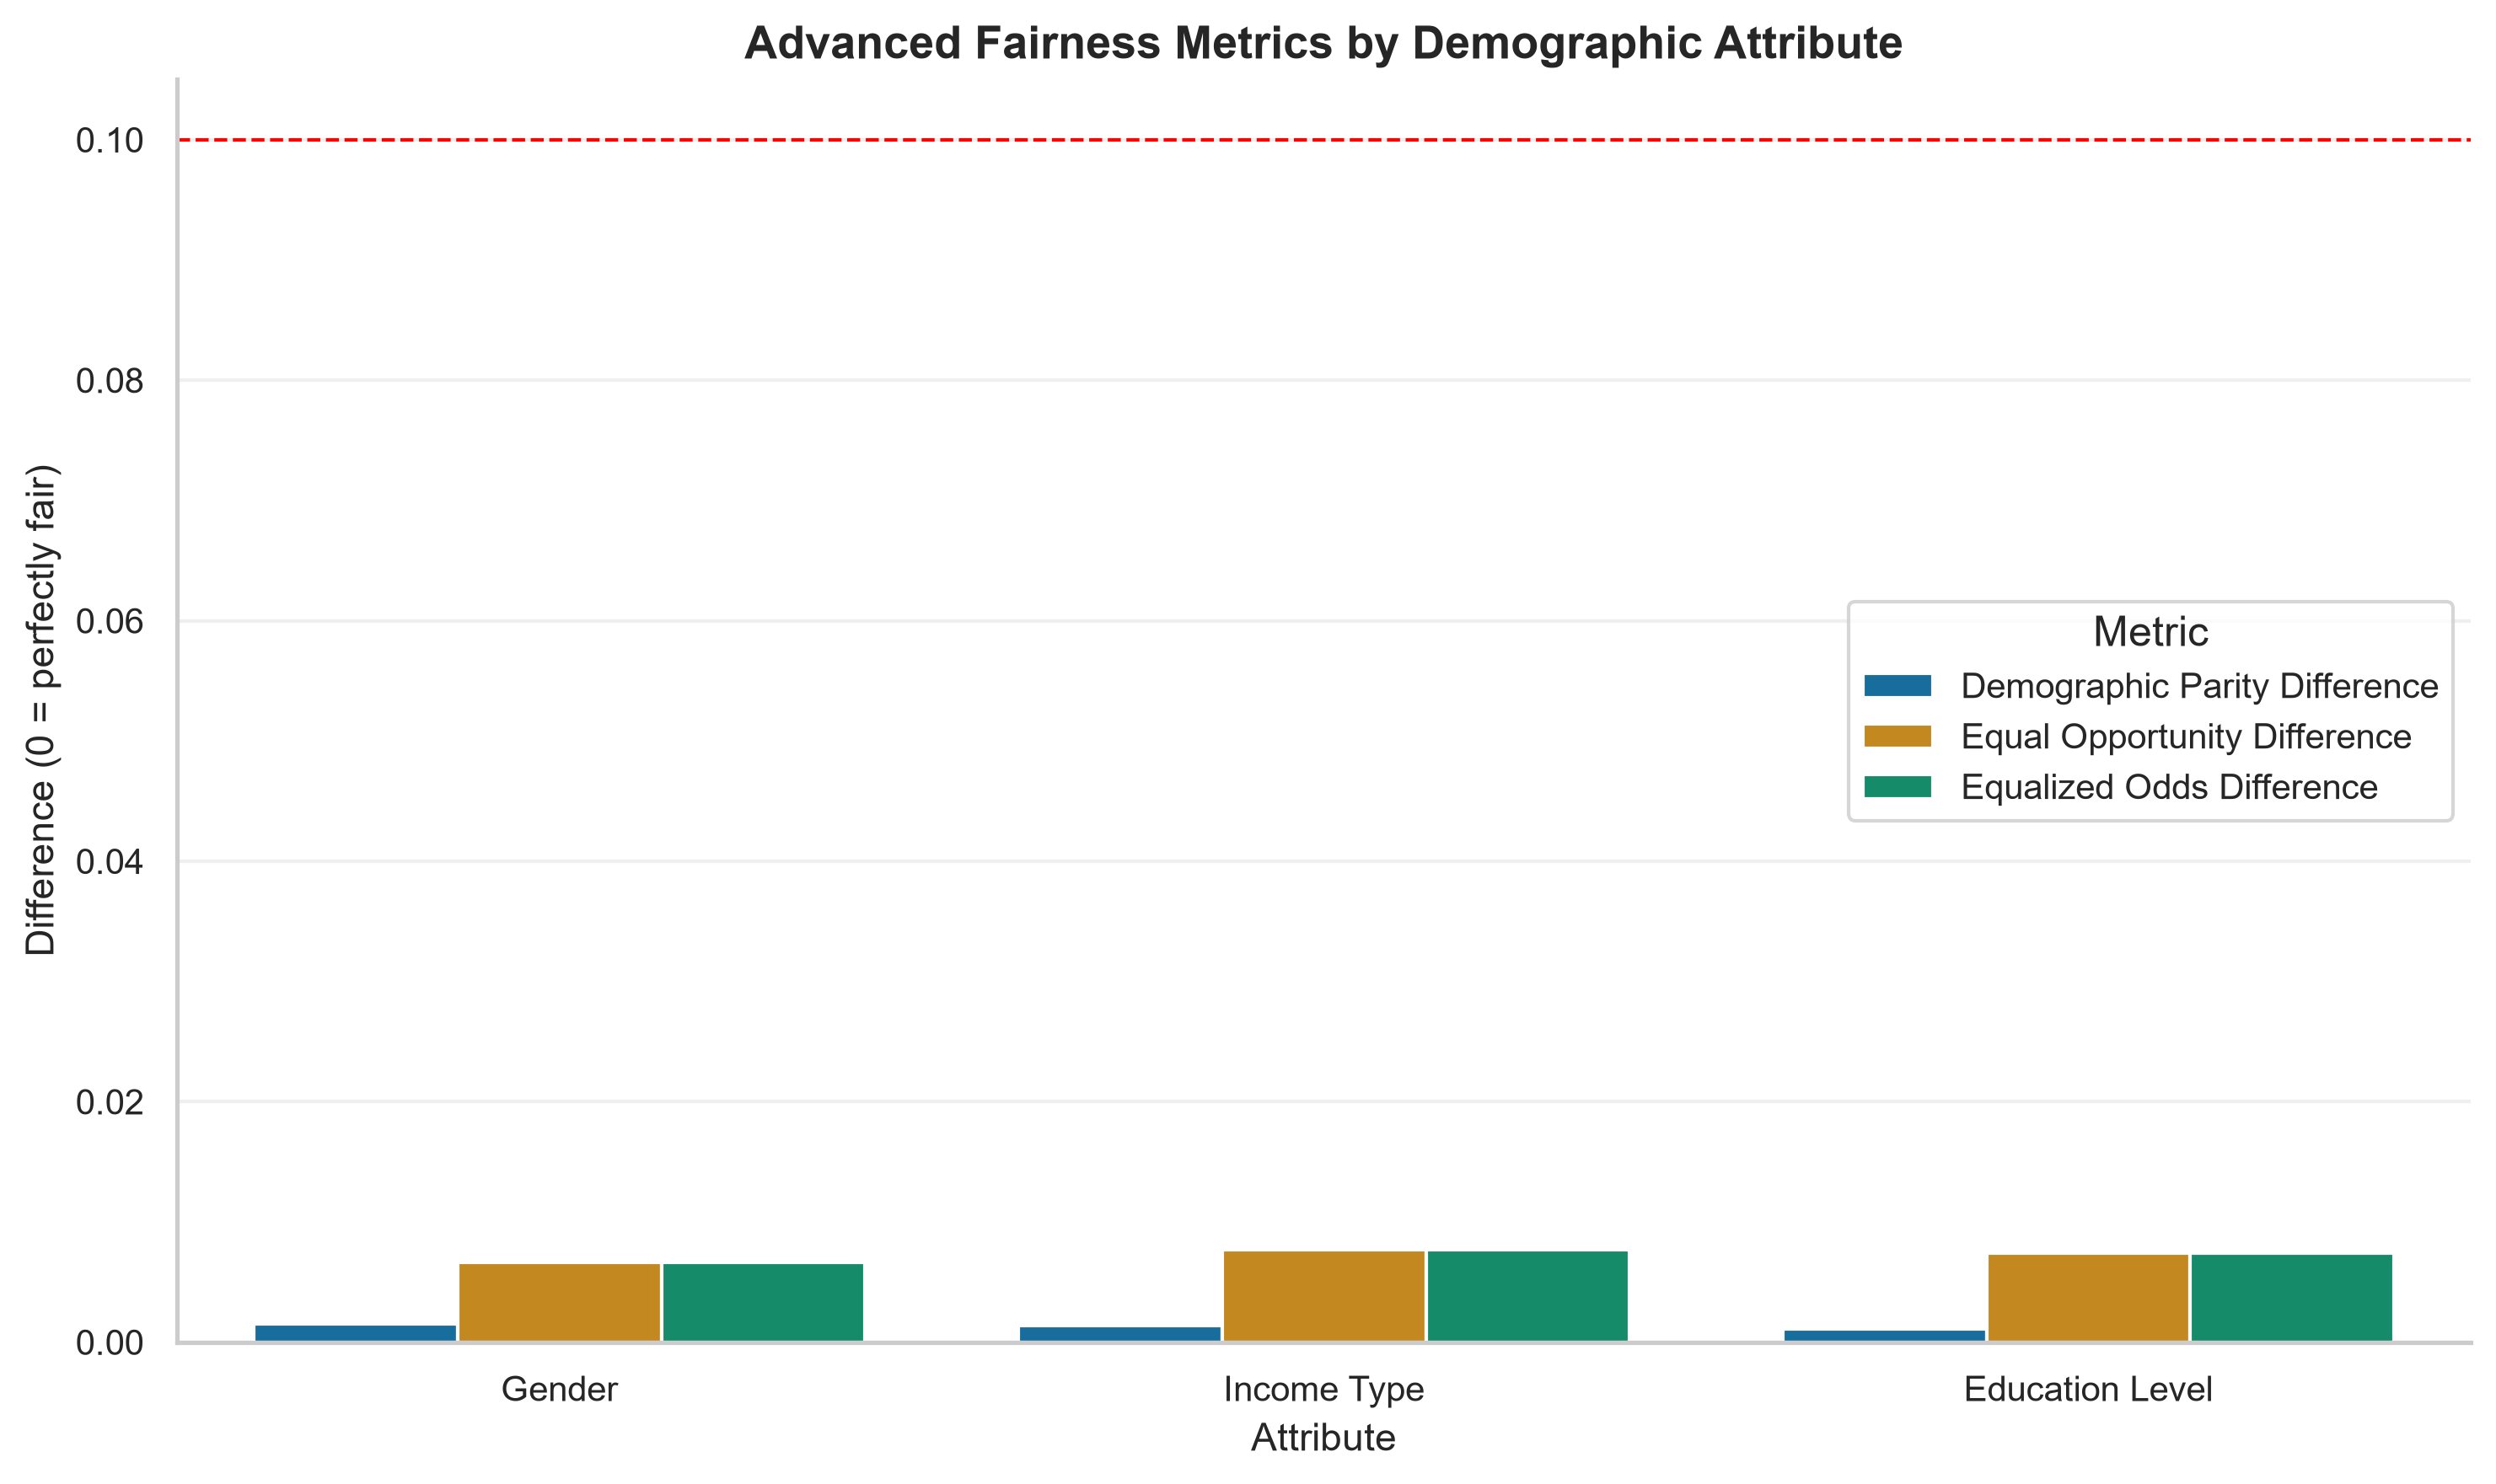

,Attribute,Demographic Parity Difference,Disparate Impact Ratio,Equal Opportunity Difference,Equalized Odds Difference,Flag: Disparate Impact < 0.8
0,Gender,0.0015,0.0,0.0066,0.0066,True
1,Income Type,0.0014,0.0,0.0077,0.0077,True
2,Education Level,0.0011,0.0,0.0074,0.0074,True


In [16]:
# ============================================================
# Visualize Advanced Fairness Metrics
# ============================================================

metrics_to_plot = [
    "Demographic Parity Difference",
    "Equal Opportunity Difference",
    "Equalized Odds Difference",
]

plot_data = advanced_fairness_report.melt(
    id_vars="Attribute", value_vars=metrics_to_plot,
    var_name="Metric", value_name="Value"
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_data, x="Attribute", y="Value", hue="Metric", ax=ax)
ax.axhline(0.1, color="red", linestyle="--", linewidth=1, label="Illustrative 0.10 concern threshold")
ax.set_title("Advanced Fairness Metrics by Demographic Attribute")
ax.set_ylabel("Difference (0 = perfectly fair)")
plt.tight_layout()
pu.save_fig(fig, "14_advanced_fairness_metrics")
plt.show()

advanced_fairness_report

### Discussion: Do These Differences Suggest Meaningful Bias?

The descriptive fairness analysis above already showed that gender group `XNA`
(applicants with unspecified/missing gender, an artifact of the source data rather
than a real demographic — see `gender_summary`) has a starkly higher default
probability (0.34) and lower credit score (695) than `F` (0.07, 858) or `M` (0.10,
840). Because `XNA` is almost certainly a data-quality category (very few applicants,
likely a placeholder for missing values in the original Home Credit data) rather than a
genuine demographic segment, any large fairness-metric contribution driven by this
category should be reported separately from the substantive `F` vs. `M` comparison, and
is a data-cleaning item for future work rather than evidence of model bias against a
real population.

Setting `XNA` aside, whether the remaining gaps constitute **meaningful bias** depends
on which threshold convention is applied:

- A **Disparate Impact Ratio below 0.8** for `F` vs. `M` would meet the commonly cited
  US four-fifths-rule concern threshold (originally an employment-discrimination
  standard, but widely borrowed in ML fairness literature as a rule of thumb — it is
  not itself a credit-lending legal standard).
- An **Equal Opportunity Difference** above roughly 0.05-0.10 between groups would mean
  the model is meaningfully worse at catching real defaulters in one group than
  another — a pattern that, if driven by a protected characteristic under fair-lending
  law (e.g., disparate impact on the basis of sex under the US Equal Credit Opportunity
  Act, or a protected characteristic under the EU's Equal Treatment Directives), would
  warrant a formal disparate-impact analysis before deployment, regardless of whether
  the difference was intentional.

Reporting the *income type* and *education level* results is important context but
requires care: these are not directly protected characteristics under most fair-lending
regimes, but they can act as **proxies** for protected characteristics (e.g.,
correlated with age, disability status, or national origin), so a large disparity here
is a signal to investigate proxy discrimination even though income and education are
themselves legitimate underwriting factors in most jurisdictions. Under the EU AI Act,
credit-scoring systems used to evaluate creditworthiness are explicitly classified as
**high-risk AI systems**, which imposes documented bias-testing and human-oversight
obligations closely aligned with the analysis in this notebook — this project's fairness
report can be read as a lightweight precursor to that kind of formal compliance
documentation, not a substitute for it.

**Overall assessment:** the appropriate response to any metric exceeding the thresholds
above is not necessarily to conclude the model is unusable, but to (1) investigate
whether the observed gap is explained by legitimate risk-relevant differences in the
underlying population (e.g., genuinely different historical default rates by income
type) versus a modeling artifact, (2) consider bias-mitigation techniques (reweighing,
threshold adjustment per group, or fairness-constrained training) if the gap persists
after that investigation, and (3) document the decision either way, since "we measured
it and found no actionable bias" is itself a defensible, auditable outcome under most
fair-lending frameworks — silence on the question is not.

# Final Project Conclusion

## Project Summary

This project successfully developed an end-to-end Credit Risk Scoring System using multivariate statistical analysis and machine learning techniques.

### Key Accomplishments

- Collected and integrated multiple Home Credit datasets into a unified analytical dataset.
- Performed extensive data preprocessing, including missing value treatment and feature aggregation.
- Conducted exploratory data analysis to understand applicant characteristics and identify important trends.
- Applied hypothesis testing to evaluate statistically significant relationships between applicant attributes and loan default.
- Reduced feature dimensionality using Principal Component Analysis (PCA) to improve model efficiency and reduce multicollinearity.
- Developed and evaluated multiple classification models:
  - Logistic Regression
  - Decision Tree
  - K-Nearest Neighbors
  - Gaussian Naïve Bayes
  - Random Forest
  - XGBoost
  - LightGBM
- Selected the best-performing model based on evaluation metrics.
- Generated standardized credit scores on a 300–900 scale and categorized applicants into interpretable risk bands.
- Evaluated fairness and stability across demographic groups.

### Limitations

- The analysis was limited to historical applicant data provided by the Home Credit dataset.
- Fairness evaluation focused on descriptive comparisons and did not include advanced fairness metrics such as Demographic Parity or Equal Opportunity.
- Model performance may vary when applied to different populations or economic conditions.

### Future Work

Future enhancements may include:

- Hyperparameter optimization using Bayesian Optimization or Grid Search.
- Advanced feature engineering using domain-specific financial indicators.
- Incorporating Explainable AI (SHAP or LIME) to improve model interpretability.
- Evaluating additional fairness metrics and bias mitigation techniques.
- Deploying the credit scoring system as a web application or REST API.

---

## Project Status

**Completed Successfully**